# Used-Car Price Prediction

**End-to-end machine learning project**

This project develops a reproducible regression workflow to estimate used-car
asking prices. It covers data validation, exploratory analysis, feature
engineering, model selection, evaluation, and practical limitations.

**Question:** Can listing attributes estimate a used car's asking price?

**Target:** `AskPrice`, recorded in Indian rupees (INR) in the supplied data.
The currency is inferred from the source values; the dataset's external provenance
and representativeness have not been independently verified. Predictions estimate
listed asking prices and should not be used as formal appraisals.

**Project objectives**
- Validate the source data and address quality issues before modeling.
- Build reproducible preprocessing and regression pipelines.
- Compare candidate models, tune parameters, and evaluate on an untouched test set.
- Communicate model performance, business relevance, and limitations.

## 1. Run instructions

Keep `used_cars_dataset.xls` beside this notebook, or change `DATA_PATH` below.
The supplied `.xls` file contains comma-separated text; the loader checks
the file signature and reads it as CSV. For a genuine Excel workbook, the same
loader uses `xlrd` for `.xls` and `openpyxl` for `.xlsx`.

Install the project dependencies in the notebook's Python environment if needed:

```text
pip install pandas numpy matplotlib scikit-learn xlrd openpyxl
```

Run the notebook from top to bottom. The split seed and model settings are fixed
for reproducibility; model scores are calculated when the notebook runs.

In [1]:
from pathlib import Path
import hashlib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import (
    KFold,
    RandomizedSearchCV,
    cross_validate,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

RANDOM_STATE = 42
DATA_PATH = Path("used_cars_dataset.xls")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 120)

print(f"pandas {pd.__version__} | scikit-learn {sklearn.__version__}")

pandas 2.3.1 | scikit-learn 1.7.0


## 2. Load and verify the source

The supplied file has an `.xls` extension but contains CSV data. The loader
detects the actual file format and selects the corresponding reader.

In [2]:
if not DATA_PATH.is_file():
    raise FileNotFoundError(
        f"Could not find {DATA_PATH.resolve()}. Put the supplied dataset beside "
        "this notebook or update DATA_PATH."
    )

with DATA_PATH.open("rb") as source_file:
    file_signature = source_file.read(8)

if file_signature.startswith(b"\xD0\xCF\x11\xE0"):
    raw = pd.read_excel(DATA_PATH, engine="xlrd")
elif file_signature.startswith(b"PK\x03\x04"):
    raw = pd.read_excel(DATA_PATH, engine="openpyxl")
else:
    raw = pd.read_csv(DATA_PATH)
    if DATA_PATH.suffix.lower() in {".xls", ".xlsx"}:
        print(
            f"Note: {DATA_PATH.name} has an Excel extension but contains text; "
            "read it as CSV."
        )

required_columns = {
    "Brand", "model", "Year", "Age", "kmDriven", "Transmission", "Owner",
    "FuelType", "PostedDate", "AdditionInfo", "AskPrice",
}
missing_columns = required_columns.difference(raw.columns)
if missing_columns:
    raise ValueError(f"Dataset is missing required columns: {sorted(missing_columns)}")

source_hash = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
print(f"Source file: {DATA_PATH.name}")
print(f"SHA-256: {source_hash}")
print(f"Raw shape: {raw.shape[0]:,} rows x {raw.shape[1]} columns")
display(raw.head())

Note: used_cars_dataset.xls has an Excel extension but contains text; read it as CSV.
Source: used_cars_dataset.xls
SHA-256: 415856e7fe34421da56b6e5363d43305f19cd63c27040f98e4b8b55d9bac5f80
Raw shape: 24,575 rows x 11 columns


,Brand,model,Year,Age,kmDriven,Transmission,Owner,FuelType,PostedDate,AdditionInfo,AskPrice
0,NaN,NaN,2001.0,23.0,"98,000 km",NaN,NaN,Unknown,Nov-24,"Honda City v teck in mint condition, valid gen...","₹ 1,95,000"
1,Toyota,NaN,NaN,15.0,190000.0 km,Manual,NaN,Diesel,Jul-24,"Toyota Innova 2.5 G (Diesel) 7 Seater, 2009, D...","₹ 3,75,000"
2,Volkswagen,NaN,2010.0,NaN,NaN,Manual,first,NaN,Nov-24,"Volkswagen Vento 2010-2013 Diesel Breeze, 2010...","₹ 1,84,999"
3,NaN,Swift,2017.0,7.0,NaN,Manual,second,Unknown,NaN,Maruti Suzuki Swift 2017 Diesel Good Condition,"₹ 5,65,000"
4,Maruti Suzuki,NaN,2019.0,5.0,NaN,Automatic,NaN,Unknown,Nov-24,"Maruti Suzuki Baleno Alpha CVT, 2019, Petrol","₹ 6,85,000"


## 3. Understand the data before changing it

`Age` and `Year` need special scrutiny: the supplied listing dates appear to be
from 2024, and the reported age may therefore be a second, fixed-reference version
of the model year. Implausible years (for example, 9999) must not be treated as
real numerical values. The checks below make those assumptions visible.

In [3]:
def parse_numeric(series):
    """Parse numeric values that may contain currency symbols, units, or separators."""
    text = (
        series.astype("string")
        .str.replace(",", "", regex=False)
        .str.replace(r"[^\d.\-]", "", regex=True)
    )
    return pd.to_numeric(text.replace("", pd.NA), errors="coerce")


raw_year = parse_numeric(raw["Year"])
raw_age = parse_numeric(raw["Age"])
raw_km = parse_numeric(raw["kmDriven"])
raw_price = parse_numeric(raw["AskPrice"])
parsed_posted_date = pd.to_datetime(
    raw["PostedDate"].astype("string").str.strip(),
    format="%b-%y",
    errors="coerce",
)

listing_reference_year = parsed_posted_date.dt.year.max()
if pd.isna(listing_reference_year):
    raise ValueError("No PostedDate values could be parsed; review the date format.")
listing_reference_year = int(listing_reference_year)

year_is_plausible = raw_year.between(1980, listing_reference_year)
age_audit_rows = year_is_plausible & raw_age.notna()
age_year_match_rate = (
    (raw_year[age_audit_rows] + raw_age[age_audit_rows] == listing_reference_year).mean()
    if age_audit_rows.any()
    else np.nan
)

quality = pd.DataFrame(
    {
        "dtype": raw.dtypes.astype(str),
        "missing": raw.isna().sum(),
        "missing_pct": (raw.isna().mean() * 100).round(1),
        "unique_non_null": raw.nunique(dropna=True),
    }
)
display(quality.sort_values("missing_pct", ascending=False))

print(f"Exact duplicate rows: {raw.duplicated().sum():,} of {len(raw):,}")
year_out_of_bounds = raw_year.notna() & ~year_is_plausible
print(
    f"Non-missing Year values outside 1980-{listing_reference_year}: "
    f"{year_out_of_bounds.sum():,} (plus {raw_year.isna().sum():,} missing)"
)
print(f"Numeric values parsed from AskPrice: {raw_price.notna().sum():,} of {len(raw):,}")
print(f"Numeric values parsed from kmDriven: {raw_km.notna().sum():,} of {len(raw):,}")
print(
    f"Among plausible years with reported Age, the share where Year + Age = "
    f"{listing_reference_year}: {age_year_match_rate:.1%}"
)

,dtype,missing,missing_pct,unique_non_null
Owner,object,10626,43.2,2
model,object,10431,42.4,403
kmDriven,object,6231,25.4,2303
PostedDate,object,6220,25.3,12
Age,float64,5975,24.3,33
Transmission,object,5922,24.1,2
Brand,object,5269,21.4,41
FuelType,object,5239,21.3,5
Year,float64,5179,21.1,36
AdditionInfo,object,0,0.0,10676


Exact duplicate rows: 9,587 of 24,575
Non-missing Year values outside 1980-2024: 5,113 (plus 5,179 missing)
Numeric values parsed from AskPrice: 24,575 of 24,575
Numeric values parsed from kmDriven: 18,344 of 24,575
Among plausible years with reported Age, the share where Year + Age = 2024: 100.0%


### Initial data-quality interpretation

- Exact full-row duplicates are removed before the train/test split, so repeated
  copies cannot appear on opposite sides of the evaluation.
- Empty and `Unknown` categories are treated as missing and imputed inside the
  training pipeline; rows are not discarded just because a predictor is absent.
- `Year` outside 1980 through the latest parseable listing year is marked missing.
  The 1980 lower bound is an explicit, adjustable screening rule—not a universal
  fact about used cars. Check it with a domain expert for a real deployment.
- `Age` is excluded because it is largely a duplicate of `Year` relative to a
  fixed 2024-era listing date. We retain `Year` instead of calculating age from
  today's date, which would silently change historical listings.
- `AdditionInfo` is free text. It is not included in this first model; text
  vectorization can be a separately evaluated extension.

## 4. Clean fields and create modeling features

The target is the advertised asking price, not a confirmed transaction price.
Numeric parsing strips rupee symbols, commas, and units (such as `km`). Dates are
reduced to listing year and month. All learned imputation and category encoding
happen later, inside cross-validation pipelines.

In [4]:
clean = raw.drop_duplicates().copy()
clean["AskPrice"] = parse_numeric(clean["AskPrice"])
clean["Year"] = parse_numeric(clean["Year"])
clean["kmDriven"] = parse_numeric(clean["kmDriven"])
clean["Age"] = parse_numeric(clean["Age"])
clean["PostedDate"] = pd.to_datetime(
    clean["PostedDate"].astype("string").str.strip(),
    format="%b-%y",
    errors="coerce",
)

year_valid = clean["Year"].between(1980, listing_reference_year)
clean["Year"] = clean["Year"].where(year_valid)
clean["kmDriven"] = clean["kmDriven"].where(clean["kmDriven"] >= 0)
clean["ListingYear"] = clean["PostedDate"].dt.year.astype(float)
clean["ListingMonth"] = clean["PostedDate"].dt.month.astype(float)

categorical_features = ["Brand", "model", "Transmission", "Owner", "FuelType"]
missing_tokens = {"", "unknown", "unk", "na", "n/a", "none", "null"}
for column in categorical_features:
    values = clean[column].astype("string").str.strip()
    values = values.mask(values.str.lower().isin(missing_tokens))
    clean[column] = values.astype(object).where(values.notna(), np.nan)

rows_before_target_check = len(clean)
clean = clean.loc[clean["AskPrice"].notna() & (clean["AskPrice"] > 0)].copy()
rows_removed_for_invalid_target = rows_before_target_check - len(clean)

numeric_features = ["Year", "kmDriven", "ListingYear", "ListingMonth"]
feature_columns = numeric_features + categorical_features
X = clean[feature_columns].copy()
y = clean["AskPrice"].astype(float).copy()

print(f"Exact duplicates removed: {len(raw) - raw.drop_duplicates().shape[0]:,}")
print(f"Rows removed for missing/non-positive target: {rows_removed_for_invalid_target:,}")
print(f"Modeling rows: {len(X):,}")
print(f"Feature count before one-hot encoding: {len(feature_columns)}")
print(f"Target range: INR {y.min():,.0f} to INR {y.max():,.0f}")
display(y.describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.99]).to_frame("AskPrice_INR"))

Exact duplicates removed: 9,587
Rows removed for missing/non-positive target: 0
Modeling rows: 14,988
Feature count before one-hot encoding: 9
Target range: INR 15,000 to INR 42,500,000


,AskPrice_INR
count,1.498800e+04
mean,9.968848e+05
std,1.586835e+06
min,1.500000e+04
25%,3.490000e+05
50%,5.700000e+05
75%,1.025000e+06
90%,1.995000e+06
99%,7.500000e+06
max,4.250000e+07


## 5. Exploratory analysis

Asking prices are strongly right-skewed, so show the price axis on a logarithmic
scale. This is only a visualization choice; the target and evaluation metrics
remain in INR. The second plot shows how listing year relates to observed median
asking price and should not be read as a causal effect.

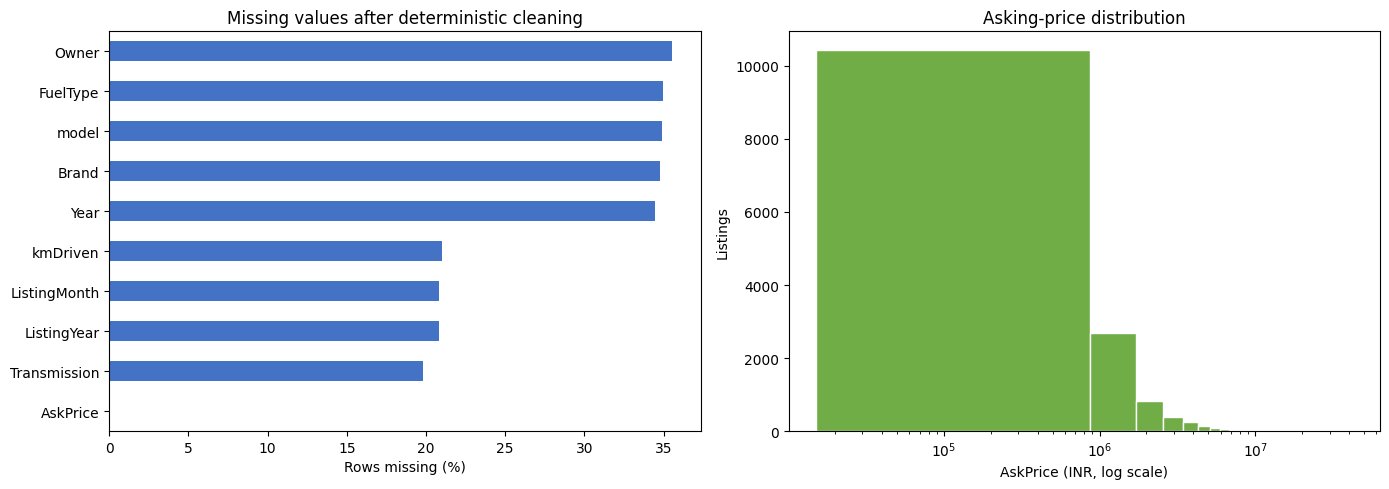

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

missing_pct = clean[feature_columns + ["AskPrice"]].isna().mean().mul(100)
missing_pct.sort_values().plot.barh(ax=axes[0], color="#4472C4")
axes[0].set_title("Missing values after deterministic cleaning")
axes[0].set_xlabel("Rows missing (%)")
axes[0].set_ylabel("")

axes[1].hist(y, bins=50, color="#70AD47", edgecolor="white")
axes[1].set_xscale("log")
axes[1].set_title("Asking-price distribution")
axes[1].set_xlabel("AskPrice (INR, log scale)")
axes[1].set_ylabel("Listings")

plt.tight_layout()
plt.show()

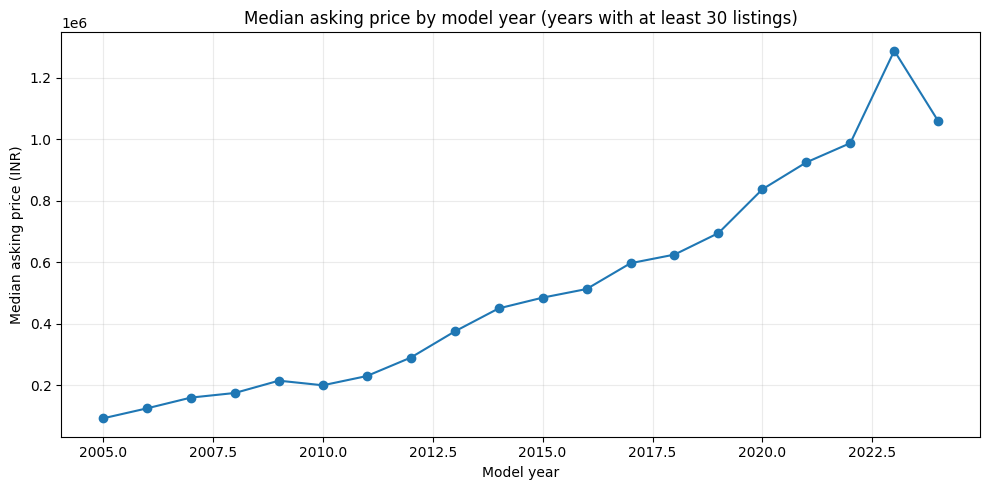

In [6]:
year_price = (
    clean.dropna(subset=["Year"])
    .groupby("Year", as_index=False)
    .agg(median_asking_price=("AskPrice", "median"), listings=("AskPrice", "size"))
)
year_price = year_price.loc[year_price["listings"] >= 30]

plt.figure(figsize=(10, 5))
plt.plot(
    year_price["Year"],
    year_price["median_asking_price"],
    marker="o",
    linewidth=1.5,
)
plt.title("Median asking price by model year (years with at least 30 listings)")
plt.xlabel("Model year")
plt.ylabel("Median asking price (INR)")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

### What the exploration can establish

Use the tables and charts above to describe the observed data, not the entire
used-car market. In particular, missing vehicle details and extreme asking prices
can affect both the learned relationships and the uncertainty of individual
predictions. The model comparison and error analysis below quantify performance
on records held out from training.

## 6. Split once; keep preprocessing inside the model

A fixed 20% holdout is reserved for the final evaluation. Cross-validation and
parameter selection use only the remaining training set. A `Pipeline` ensures that
each fold learns its own medians, scaling values, and category vocabulary; this
prevents information from validation/test rows leaking into preprocessing.

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
)

numeric_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
        ("scaler", StandardScaler()),
    ]
)

categorical_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="constant", fill_value="Missing")),
        (
            "one_hot",
            OneHotEncoder(
                handle_unknown="ignore",
                min_frequency=10,
            ),
        ),
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_pipeline, numeric_features),
        ("categorical", categorical_pipeline, categorical_features),
    ],
    remainder="drop",
)


def make_model_pipeline(regressor):
    return Pipeline(
        steps=[
            ("preprocess", preprocessor),
            ("model", regressor),
        ]
    )


print(f"Training rows: {len(X_train):,} | final test rows: {len(X_test):,}")

Training rows: 11,990 | final test rows: 2,998


## 7. Compare models with cross-validation

The median predictor is a simple baseline. Ridge regression tests a regularized
linear relationship; the random forest tests nonlinear interactions. Mean
absolute error (MAE) is the primary selection metric because it is interpretable
as a typical absolute error in INR. RMSE penalizes occasional large misses more;
R-squared is a supplementary goodness-of-fit measure, not a percentage accuracy.

In [8]:
candidate_models = {
    "Ridge": Ridge(alpha=10.0),
    "Random forest": RandomForestRegressor(
        n_estimators=100,
        min_samples_leaf=2,
        random_state=RANDOM_STATE,
        n_jobs=-1,
    ),
}

cv = KFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
scoring = {
    "mae": "neg_mean_absolute_error",
    "rmse": "neg_root_mean_squared_error",
    "r2": "r2",
}

comparison_rows = []
for name, estimator in candidate_models.items():
    scores = cross_validate(
        make_model_pipeline(estimator),
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=1,
        return_train_score=False,
    )
    comparison_rows.append(
        {
            "Model": name,
            "CV MAE (INR)": -scores["test_mae"].mean(),
            "CV MAE std (INR)": scores["test_mae"].std(),
            "CV RMSE (INR)": -scores["test_rmse"].mean(),
            "CV R-squared": scores["test_r2"].mean(),
        }
    )

comparison = pd.DataFrame(comparison_rows).set_index("Model").sort_values("CV MAE (INR)")
display(comparison.round(3))
selected_name = comparison.index[0]
print(f"Selected for tuning by training-fold MAE: {selected_name}")

,CV MAE (INR),CV MAE std (INR),CV RMSE (INR),CV R-squared
Model,,,,
Random forest,483732.882,10290.428,1293866.544,0.307
Ridge,572362.878,6533.023,1297580.137,0.304


Selected for tuning by training-fold MAE: Random forest


## 8. Tune the selected model using training data only

This small randomized search is intentionally bounded so the notebook remains
practical to run in a classroom. A larger search is not automatically better;
broaden it only when the extra compute is justified and keep the final test set
untouched.

In [9]:
selected_estimator = candidate_models[selected_name]
if selected_name == "Ridge":
    parameter_space = {"model__alpha": [0.1, 1.0, 10.0, 100.0]}
else:
    parameter_space = {
        "model__max_depth": [None, 16, 24],
        "model__min_samples_leaf": [1, 2, 4],
    }

search = RandomizedSearchCV(
    estimator=make_model_pipeline(selected_estimator),
    param_distributions=parameter_space,
    n_iter=4,
    scoring="neg_mean_absolute_error",
    cv=cv,
    random_state=RANDOM_STATE,
    n_jobs=1,
    refit=True,
)
search.fit(X_train, y_train)
final_model = search.best_estimator_

print(f"Best CV MAE after tuning: INR {-search.best_score_:,.0f}")
print(f"Best parameters: {search.best_params_}")

Best CV MAE after tuning: INR 480,151
Best parameters: {'model__min_samples_leaf': 1, 'model__max_depth': None}


## 9. Final test-set evaluation

Only now is the holdout used. The baseline uses the training-set median, never the
test-set target. The reported metrics are in original INR units.

In [10]:
test_predictions = final_model.predict(X_test)
baseline_predictions = np.full(len(y_test), y_train.median())


def regression_metrics(actual, predicted):
    return {
        "MAE (INR)": mean_absolute_error(actual, predicted),
        "RMSE (INR)": np.sqrt(mean_squared_error(actual, predicted)),
        "R-squared": r2_score(actual, predicted),
    }


test_results = pd.DataFrame(
    [
        {"Model": "Training-median baseline", **regression_metrics(y_test, baseline_predictions)},
        {"Model": f"Tuned {selected_name}", **regression_metrics(y_test, test_predictions)},
    ]
).set_index("Model")
test_results["MAE / test median price"] = (
    test_results["MAE (INR)"] / y_test.median()
)
display(test_results.round(3))

,MAE (INR),RMSE (INR),R-squared,MAE / test median price
Model,,,,
Training-median baseline,678666.764,1763281.489,-0.072,1.170
Tuned Random forest,453857.482,1377032.088,0.346,0.783


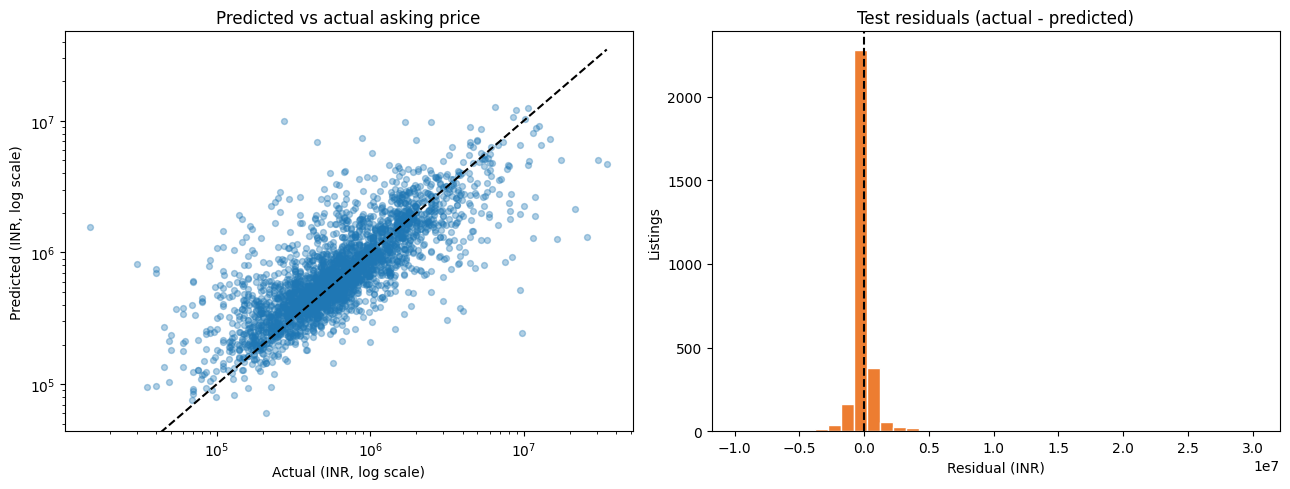

In [11]:
error_analysis = pd.DataFrame(
    {
        "Actual": y_test.to_numpy(),
        "Predicted": test_predictions,
    },
    index=y_test.index,
)
error_analysis["Residual"] = error_analysis["Actual"] - error_analysis["Predicted"]
error_analysis["AbsoluteError"] = error_analysis["Residual"].abs()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(
    error_analysis["Actual"],
    error_analysis["Predicted"],
    alpha=0.35,
    s=18,
)
plot_limit = max(error_analysis["Actual"].max(), error_analysis["Predicted"].max())
axes[0].plot([0, plot_limit], [0, plot_limit], linestyle="--", color="black")
axes[0].set_xscale("log")
axes[0].set_yscale("log")
axes[0].set_title("Predicted vs actual asking price")
axes[0].set_xlabel("Actual (INR, log scale)")
axes[0].set_ylabel("Predicted (INR, log scale)")

axes[1].hist(error_analysis["Residual"], bins=40, color="#ED7D31", edgecolor="white")
axes[1].axvline(0, color="black", linestyle="--")
axes[1].set_title("Test residuals (actual - predicted)")
axes[1].set_xlabel("Residual (INR)")
axes[1].set_ylabel("Listings")

plt.tight_layout()
plt.show()

In [12]:
error_analysis["Actual price quartile"] = pd.qcut(
    error_analysis["Actual"],
    q=4,
    duplicates="drop",
)
segment_errors = (
    error_analysis.groupby("Actual price quartile", observed=True)
    .agg(
        listings=("AbsoluteError", "size"),
        median_actual_INR=("Actual", "median"),
        MAE_INR=("AbsoluteError", "mean"),
        median_absolute_error_INR=("AbsoluteError", "median"),
    )
)
display(segment_errors.round(0))

,listings,median_actual_INR,MAE_INR,median_absolute_error_INR
Actual price quartile,,,,
"(14999.999, 350000.0]",766,230000.0,201838.0,91827.0
"(350000.0, 580000.0]",735,465000.0,176233.0,85360.0
"(580000.0, 1050000.0]",756,749500.0,276703.0,143585.0
"(1050000.0, 34800000.0]",741,1749999.0,1170497.0,549240.0


### Interpreting the evaluation responsibly

- Compare the tuned model with the training-median baseline. A more complex model
  is useful only if it improves the held-out results enough to justify its cost.
- Read MAE as a typical absolute miss in INR, not as the accuracy of every quote.
  RMSE is more sensitive to the expensive outliers in this skewed dataset.
- Segment errors can expose uneven performance across price ranges. Inspect the
  plots and individual residuals before making a claim about a particular buyer.
- The random split estimates performance on a similar mixture of listings. It does
  not prove performance on future months, a different region, or unseen car types.

## 10. Demonstrate a prediction

This predicts one held-out row to show how the fitted pipeline handles the same
feature schema. It is an illustration, not a new appraisal.

In [13]:
example = X_test.iloc[[0]]
example_prediction = float(final_model.predict(example)[0])
example_actual = float(y_test.iloc[0])

print(f"Predicted asking price: INR {example_prediction:,.0f}")
print(f"Observed asking price:  INR {example_actual:,.0f}")
print(f"Absolute error:         INR {abs(example_actual - example_prediction):,.0f}")
display(example)

Predicted asking price: INR 2,929,670
Observed asking price:  INR 1,925,000
Absolute error:         INR 1,004,670


,Year,kmDriven,ListingYear,ListingMonth,Brand,model,Transmission,Owner,FuelType
5995,<NA>,60000.0,NaN,NaN,Mercedes-Benz,GLA,Automatic,NaN,NaN


## 11. Conclusion and future work

The source contains 24,575 rows, including 9,587 exact duplicate records. After
deduplication and data validation, 14,988 listings were available for modeling.
Reported `Age` matches `2024 - Year` for all records with plausible years and both
values present, so `Age` was excluded as redundant. Implausible model years were
treated as missing and imputed within the training pipeline.

In the seeded run shown here, Random Forest had the lowest cross-validation MAE.
On the 2,998-row holdout, its MAE was **INR 453,857**, compared with **INR 678,667**
for the training-median baseline; the model's R-squared was 0.346. Errors were
largest in the highest-price quartile, indicating less reliable estimates for
expensive listings. MAE and RMSE should be interpreted in the context of the
dataset's highly skewed asking prices.

This random holdout estimates performance on a similar mix of listings; it does
not establish performance in future months, other regions, or on unseen vehicle
types. The data contains asking prices rather than verified transaction prices,
and its external provenance is unknown. Before deployment, evaluate on a later
time period, verify the market and currency, and obtain reliable transaction and
geographic data. Additional experiments could incorporate listing text through a
train-fitted text pipeline and compare gradient-boosted tree models.

## References

Method choices follow the official scikit-learn documentation:

- [Pipelines and composite estimators](https://scikit-learn.org/stable/modules/compose.html):
  fit preprocessing within each training fold to avoid leakage.
- [Cross-validation](https://scikit-learn.org/stable/modules/cross_validation.html):
  keep a final test set out of model/parameter selection.
- [Metrics and scoring](https://scikit-learn.org/stable/modules/model_evaluation.html#regression-metrics):
  choose regression metrics for the prediction objective and interpret them in context.
- [OneHotEncoder](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html):
  encode categories while handling values not seen during fitting.

Dataset: the supplied `used_cars_dataset.xls` file.